# Лабораторная работа 4 Кластеризация
К. Р. Халикова, группа 4417. Вариант 1.

Цель: изучение алгоритмов и методов кластеризации на практике.

## Часть 1 Синтетический набор данных
Используется функция make_data из методички без изменения алгоритма. Выбрано n = 100 объектов на группу, seed = 21. Всего создаются 300 объектов. Все модели обучаются на стандартизованных данных; координаты центров для рисунков переводятся обратно в исходные единицы.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def make_data(n, seed):
    np.random.seed(seed)
    shift_matrix = np.array([[3, 3], [6, 9], [9, 3]])
    data = np.random.randn(3, 2, n) + shift_matrix.reshape((3, 2, 1))
    data = np.swapaxes(data, 1, 2)
    data = data.reshape((-1, 2))
    data *= np.array([[20, 0.5]])
    df = pd.DataFrame({'x': data[:, 0], 'y': data[:, 1]},
                      columns=['x', 'y'])
    df = df.sample(frac=1.0)
    return df

df = make_data(100, 21)
display(df.head())
print('Количество объектов:', len(df))
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

Количество объектов: 300


,x,y
236,195.766368,1.362341
260,155.199288,0.749502
251,194.170649,1.131834
246,199.602012,2.807162
174,108.301062,4.583723


### Кластеризация при k = 3, 2, 4
Для каждого числа кластеров применяется fit_predict. Метки обозначают принадлежность к группе и не являются истинными классами. n_init = 10 задаёт десять инициализаций из числа описанных в методичке; random_state = 21 обеспечивает воспроизводимость. Силуэт рассчитывается в том же стандартизованном пространстве, где обучалась модель.

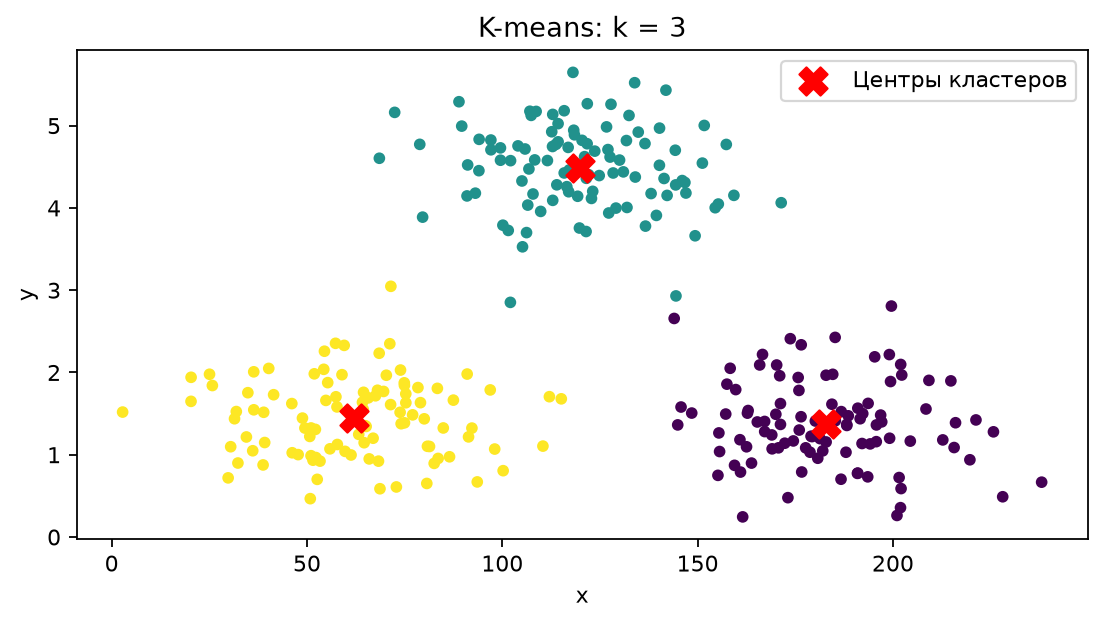

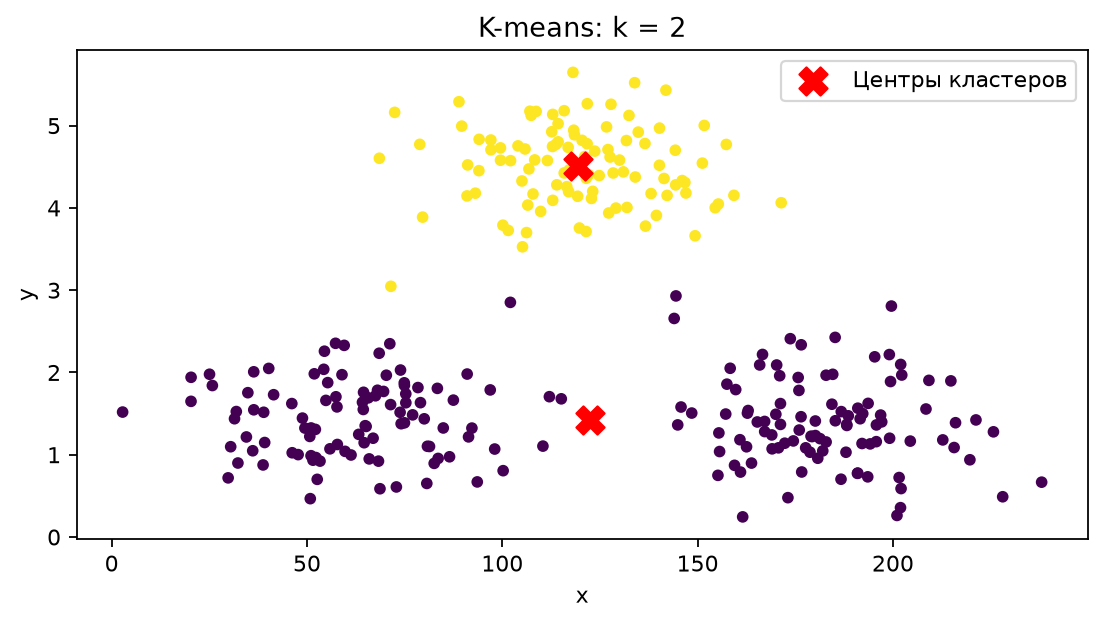

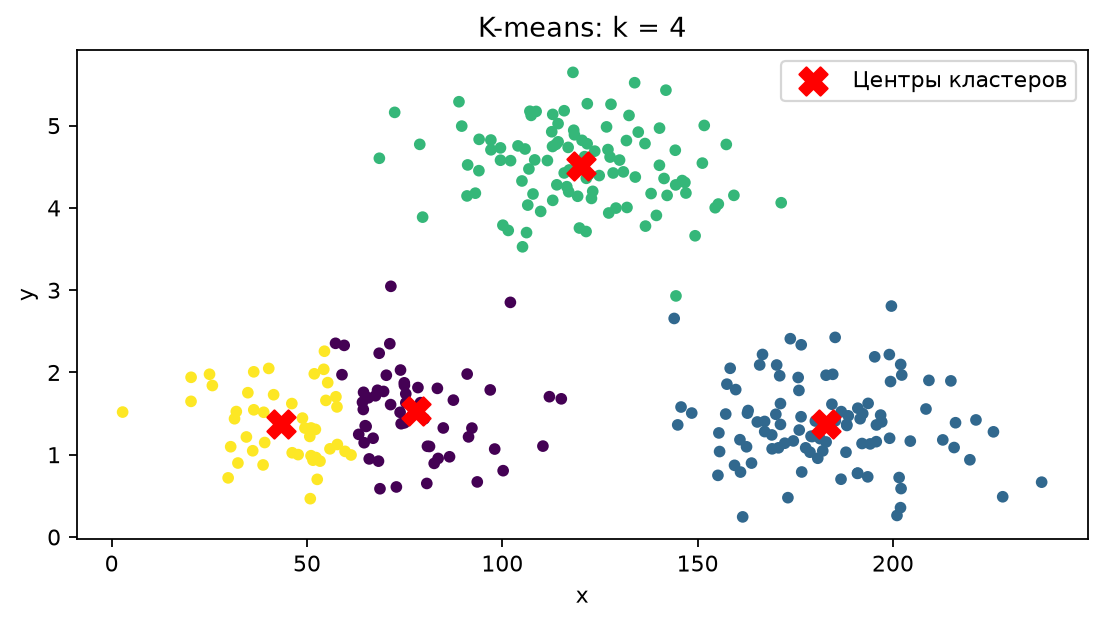

,silhouette
k,
3,0.703422
2,0.488711
4,0.573960


In [2]:
part1_rows = []
part1_models = {}
for k in [3, 2, 4]:
    model = KMeans(n_clusters=k, n_init=10, random_state=21)
    labels = model.fit_predict(X_scaled)
    part1_models[k] = model
    part1_rows.append({'k': k, 'silhouette': silhouette_score(X_scaled, labels)})
    centers = scaler.inverse_transform(model.cluster_centers_)
    plt.figure(figsize=(7, 4))
    plt.scatter(df.x, df.y, c=labels, cmap='viridis', s=18)
    plt.scatter(centers[:, 0], centers[:, 1], c='red',
                marker='X', s=160, label='Центры кластеров')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'K-means: k = {k}')
    plt.legend()
    plt.tight_layout()
    plt.show()
part1_metrics = pd.DataFrame(part1_rows).set_index('k')
display(part1_metrics)

При k = 3 получен силуэт 0,7034, при k = 2 - 0,4887, при k = 4 - 0,5740. Разбиение на три кластера наиболее согласуется с тремя группами, заданными функцией генерации. При двух кластерах группы объединяются, при четырех одна из групп дробится.

### Метод локтя
Для k от 1 до 9 рассчитывается inertia_: сумма квадратов расстояний до центров в стандартизованном пространстве. Перегиб кривой сопоставляется с результатами силуэта.

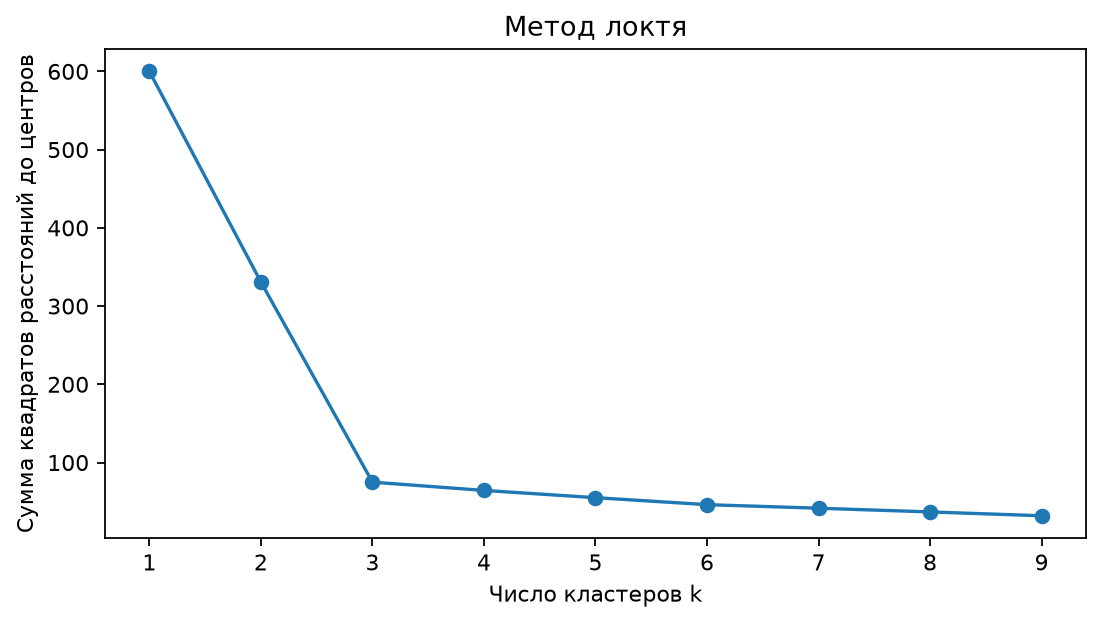

In [3]:
inertia = []
for k in range(1, 10):
    model = KMeans(n_clusters=k, n_init=10, random_state=21)
    model.fit(X_scaled)
    inertia.append(model.inertia_)
plt.figure(figsize=(7, 4))
plt.plot(range(1, 10), inertia, marker='o')
plt.xlabel('Число кластеров k')
plt.ylabel('Сумма квадратов расстояний до центров')
plt.title('Метод локтя')
plt.xticks(range(1, 10))
plt.tight_layout()
plt.show()

На кривой inertia основной перегиб соответствует k = 3. Этот результат согласуется с максимальным силуэтом среди k = 2, 3, 4.

## Часть 2 Медицинские данные Вариант 1
Набор medical_diagnosis.csv содержит возраст, пол, индекс массы тела, давление, холестерин, глюкозу, статус курения, наследственность, физическую активность, выраженность симптомов, CRP, лейкоциты и результат ЭКГ. Disease обозначает исходный класс: 1 - заболевание, 0 - отсутствие заболевания по разметке файла.

### Загрузка и предварительная обработка
Проверяются типы, пропуски, полные дубликаты и описательные статистики. Полные дубликаты удаляются. Пропуски отсутствуют, поэтому заполнение не применяется. Высокие значения лабораторных показателей сохраняются: статистическая необычность сама по себе не доказывает ошибку измерения. Результат кластеризации исследуется с учетом их влияния.

In [4]:
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
from sklearn.metrics import homogeneity_score, completeness_score
from scipy.cluster.hierarchy import linkage, dendrogram

medical = pd.read_csv('medical_diagnosis.csv')
print('Размер исходных данных:', medical.shape)
medical.info()
print('Пропуски:', medical.isna().sum().sum())
print('Полные дубликаты:', medical.duplicated().sum())
medical = medical.drop_duplicates().copy()
print('Размер после удаления дубликатов:', medical.shape)
display(medical.describe().round(3))
print('Количество объектов классов:')
display(medical['Disease'].value_counts().sort_index())

Размер исходных данных: (3031, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3031 entries, 0 to 3030
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    3031 non-null   int64  
 1   sex                    3031 non-null   object 
 2   BMI                    3031 non-null   float64
 3   systolic_bp            3031 non-null   float64
 4   cholesterol_mg_dl      3031 non-null   float64
 5   fasting_glucose_mg_dl  3031 non-null   float64
 6   smoking_status         3031 non-null   object 
 7   family_history         3031 non-null   object 
 8   activity_level         3031 non-null   object 
 9   symptom_score          3031 non-null   float64
 10  CRP_mg_L               3031 non-null   float64
 11  WBC_10e9_L             3031 non-null   float64
 12  ECG_result             3031 non-null   object 
 13  Disease                3031 non-null   int64  
dtypes: float64(7), int64(

,age,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,symptom_score,CRP_mg_L,WBC_10e9_L,Disease
count,3030.000,3030.000,3030.000,3030.000,3030.000,3030.000,3030.000,3030.000,3030.000
mean,53.178,26.466,122.414,202.667,94.367,2.040,1.373,6.823,0.016
std,20.743,5.871,17.862,53.573,19.550,1.358,3.131,1.978,0.126
min,18.000,13.500,82.000,85.000,56.000,0.000,0.100,2.300,0.000
25%,35.000,22.500,110.000,171.000,80.250,1.000,0.100,5.480,0.000
50%,53.000,26.300,122.000,200.000,94.000,2.000,0.520,6.750,0.000
75%,71.000,30.400,134.000,232.000,107.000,3.000,1.460,8.150,0.000
max,89.000,50.900,184.000,658.200,163.000,6.800,43.450,13.720,1.000


Disease
0    2981
1      49
Name: count, dtype: int64

### Выделение целевого класса и матрица диаграмм
Disease используется только для окраски исходных наблюдений и внешних метрик. Из X исключены Disease и пять категориальных столбцов: sex, smoking_status, family_history, activity_level, ECG_result. Основное задание выполняется по восьми числовым признакам; кодирование категорий относится к дополнительным заданиям методички.

В матрице каждая точка соответствует пациенту, цвет обозначает Disease. Краткие названия сохраняют порядок исходных числовых признаков: возраст, BMI, давление, холестерин, глюкоза, симптомы, CRP, лейкоциты.

Признаки модели: ['age', 'BMI', 'systolic_bp', 'cholesterol_mg_dl', 'fasting_glucose_mg_dl', 'symptom_score', 'CRP_mg_L', 'WBC_10e9_L']


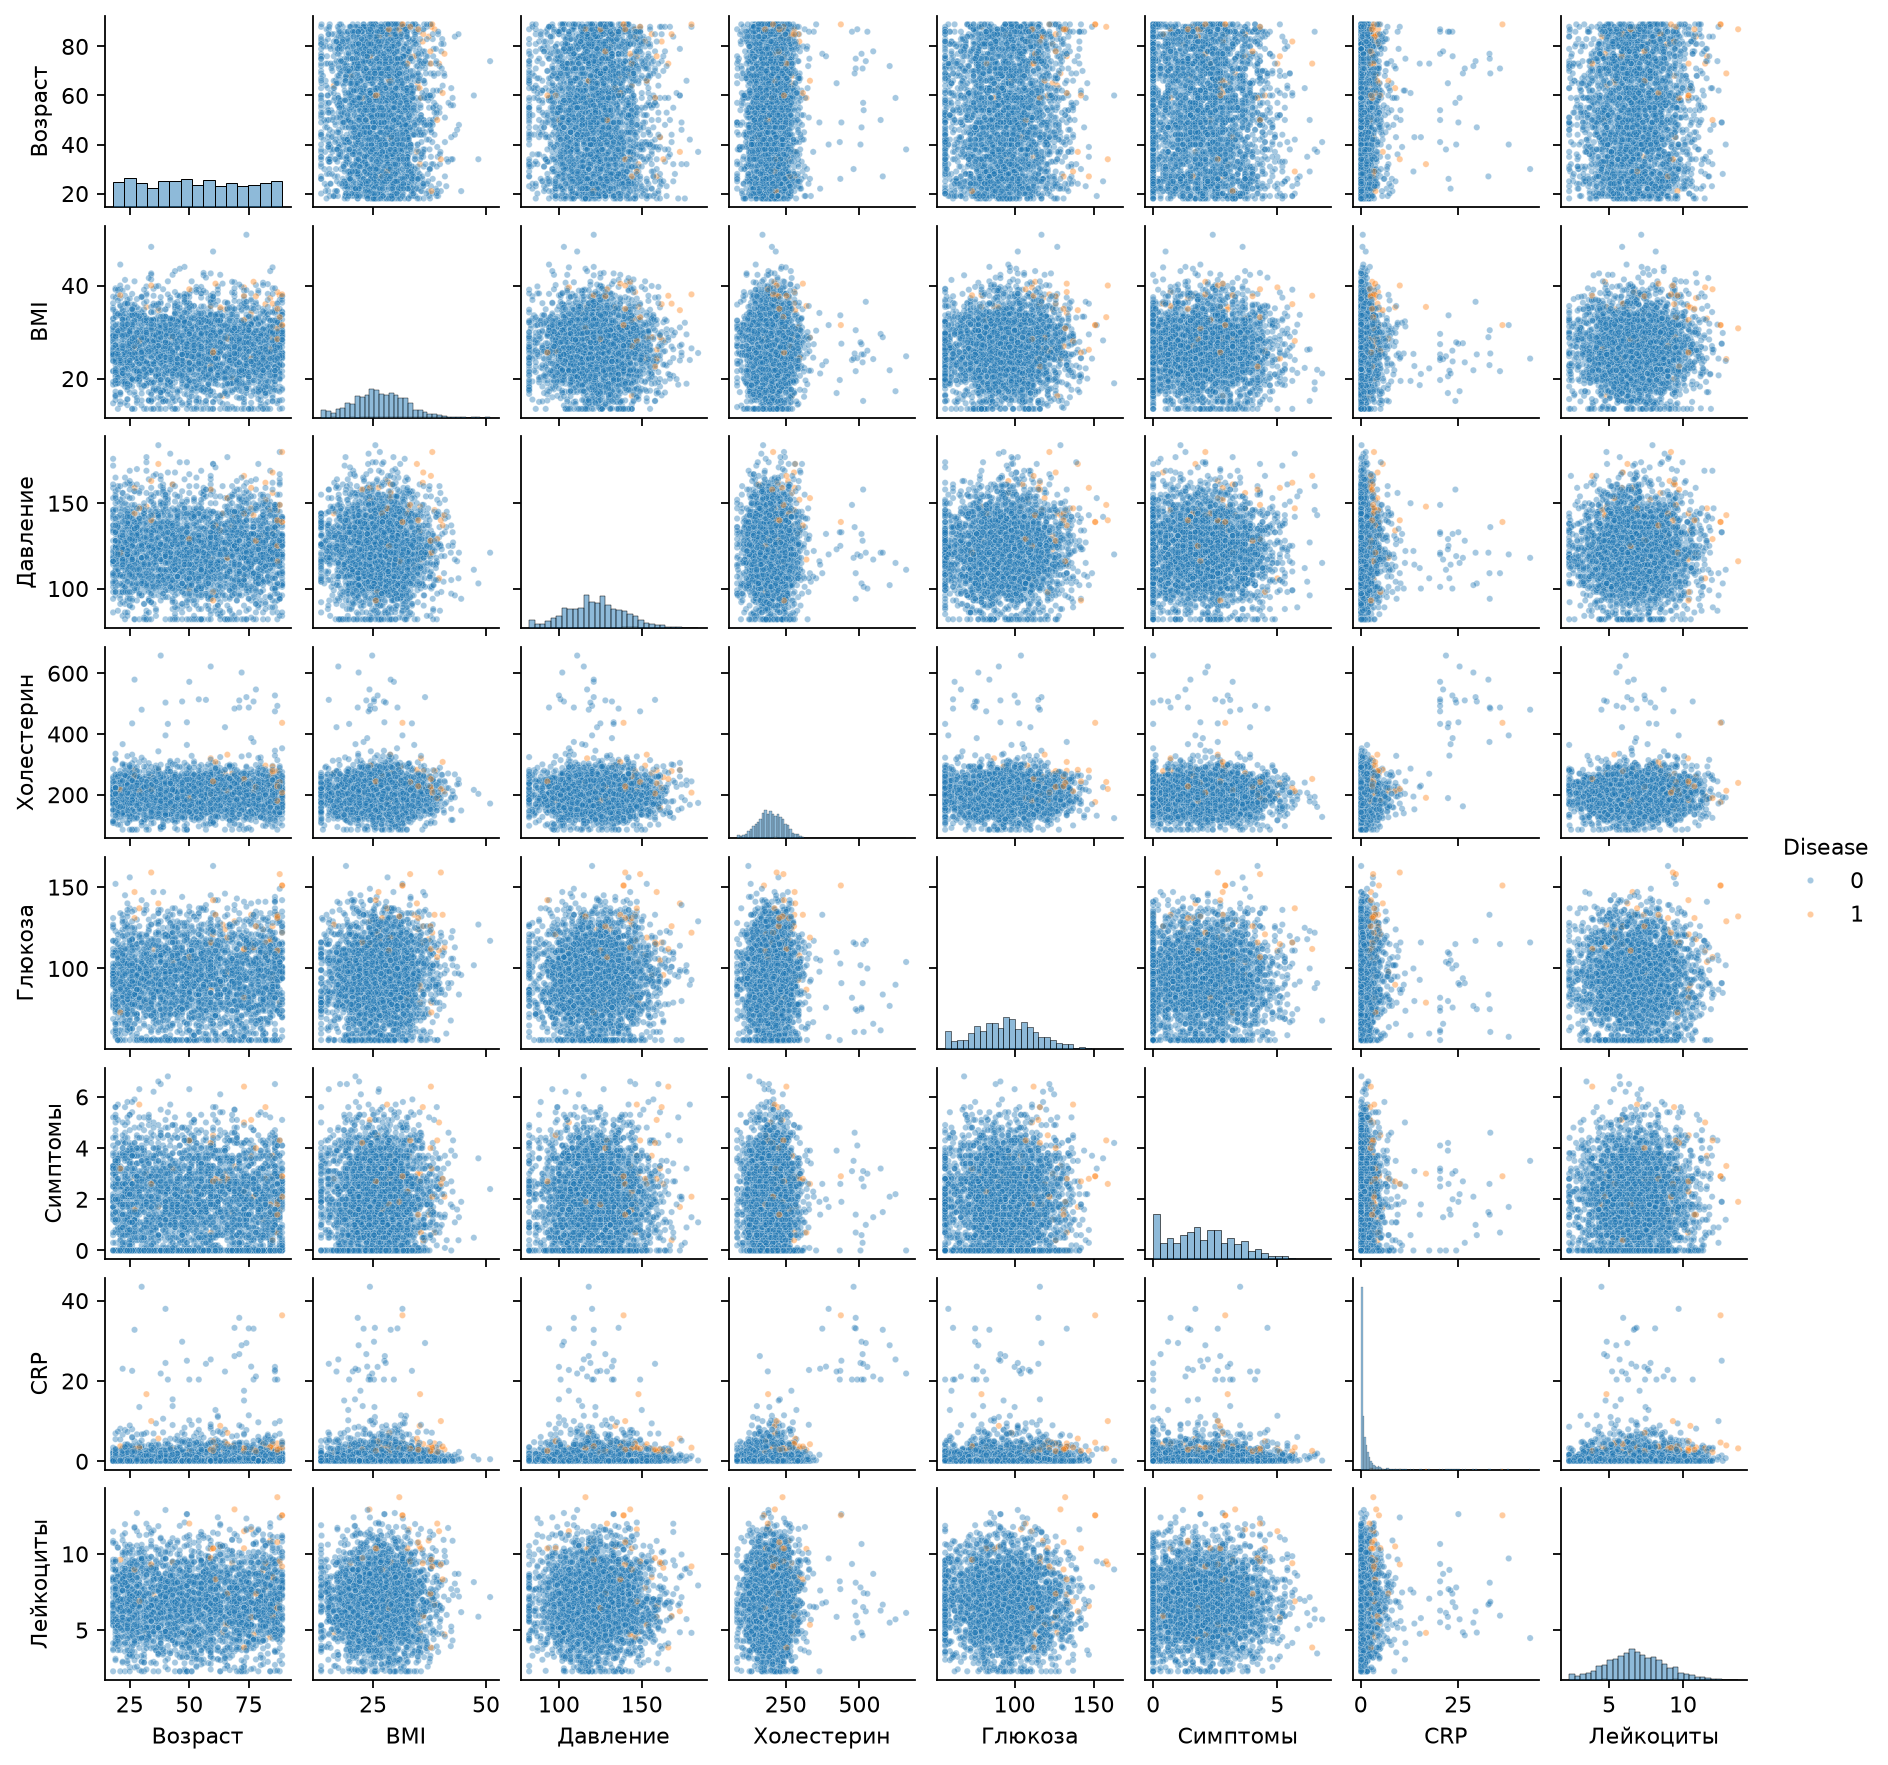

In [5]:
y_true = medical['Disease']
X = medical.drop(columns='Disease').select_dtypes(include='number')
print('Признаки модели:', X.columns.tolist())
pair_data = X.rename(columns={
    'age': 'Возраст', 'systolic_bp': 'Давление',
    'cholesterol_mg_dl': 'Холестерин',
    'fasting_glucose_mg_dl': 'Глюкоза', 'symptom_score': 'Симптомы',
    'CRP_mg_L': 'CRP', 'WBC_10e9_L': 'Лейкоциты'})
pair_data['Disease'] = y_true
sns.pairplot(pair_data, hue='Disease', diag_kind='hist',
             plot_kws={'s': 8, 'alpha': 0.4}, height=1.4)
plt.show()
scaler_medical = StandardScaler()
X_medical_scaled = scaler_medical.fit_transform(X)

### K-means и выбор числа кластеров
Сравниваются k от 2 до 9 по среднему силуэту в стандартизованном пространстве. Выбирается k с максимальным силуэтом; inertia используется как дополнительный графический ориентир. Disease при выборе числа кластеров не используется. Кластеризация выполняется на всех подготовленных объектах: обучение без учителя не требует разбиения train/test для данного задания.

Выбранное число кластеров: 2


,inertia,silhouette
k,,
2,21918.0580,0.1068
3,20511.6964,0.0907
4,17741.1248,0.1003
5,16628.4537,0.1007
6,15740.0508,0.1007
7,15001.0696,0.1015
8,14434.8283,0.1025
9,13990.3717,0.1023


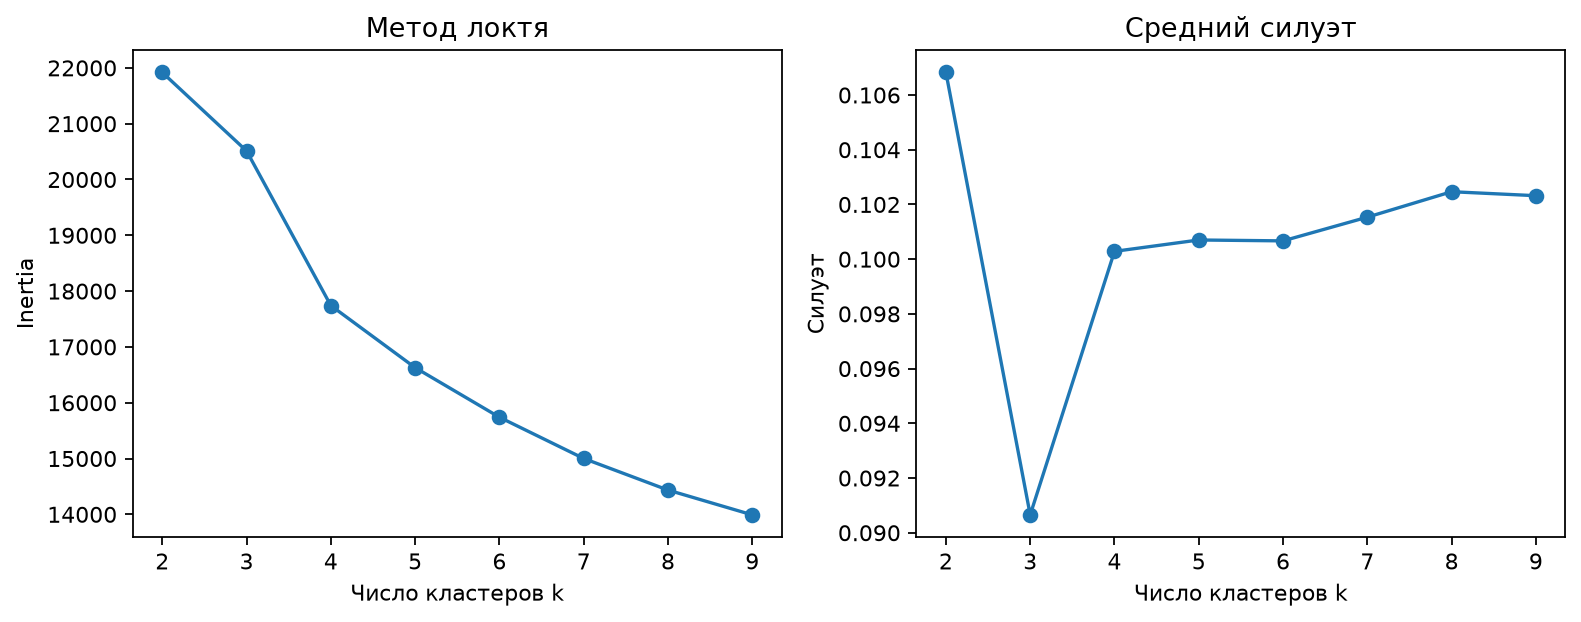

In [6]:
selection_rows = []
medical_models = {}
for k in range(2, 10):
    model = KMeans(n_clusters=k, n_init=10, random_state=21)
    labels = model.fit_predict(X_medical_scaled)
    medical_models[k] = model
    selection_rows.append({'k': k, 'inertia': model.inertia_,
                           'silhouette': silhouette_score(X_medical_scaled, labels)})
selection = pd.DataFrame(selection_rows).set_index('k')
display(selection.round(4))
best_k = int(selection['silhouette'].idxmax())
kmeans_medical = medical_models[best_k]
labels_kmeans = kmeans_medical.labels_
print('Выбранное число кластеров:', best_k)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(selection.index, selection.inertia, marker='o')
axes[0].set(xlabel='Число кластеров k', ylabel='Inertia', title='Метод локтя')
axes[1].plot(selection.index, selection.silhouette, marker='o')
axes[1].set(xlabel='Число кластеров k', ylabel='Силуэт', title='Средний силуэт')
plt.tight_layout()
plt.show()

Максимальный силуэт среди проверенных k = 2-9 получен при k = 2: 0,1068. Значение невелико, поэтому выраженного разделения основной массы данных не обнаружено. На графике inertia нет убедительного отдельного локтя; выбор k = 2 основан на сравнении силуэтов.

### Состав кластеров и средние показатели K-means
Каждому исходному объекту назначается метка cluster. Выводятся номера объектов и метки, численность групп и средние всех восьми признаков в исходных единицах. Номер кластера условен и не равен Disease. Для внешней оценки рассчитываются ARI, AMI, однородность и полнота; для внутренней оценки используется силуэт.

In [7]:
assignments_kmeans = medical.copy()
assignments_kmeans['cluster'] = labels_kmeans
display(assignments_kmeans[['Disease', 'cluster']])
print('Численность кластеров K-means:')
display(assignments_kmeans.groupby('cluster').size().rename('count'))
means_kmeans = assignments_kmeans.groupby('cluster')[X.columns].mean()
display(means_kmeans.round(3))
metrics_kmeans = pd.Series({
    'silhouette': silhouette_score(X_medical_scaled, labels_kmeans),
    'ARI': adjusted_rand_score(y_true, labels_kmeans),
    'AMI': adjusted_mutual_info_score(y_true, labels_kmeans),
    'homogeneity': homogeneity_score(y_true, labels_kmeans),
    'completeness': completeness_score(y_true, labels_kmeans)})
display(metrics_kmeans.round(5))

Численность кластеров K-means:


,Disease,cluster
0,0,0
1,0,0
2,0,0
3,0,1
4,0,1
...,...,...
3026,0,1
3027,0,1
3028,0,1
3029,0,1


cluster
0    1587
1    1443
Name: count, dtype: int64

,age,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,symptom_score,CRP_mg_L,WBC_10e9_L
cluster,,,,,,,,
0,36.645,26.982,122.628,196.292,92.609,2.155,0.992,6.633
1,71.360,25.897,122.179,209.679,96.301,1.914,1.792,7.033


silhouette      0.10682
ARI             0.00197
AMI             0.00644
homogeneity     0.03214
completeness    0.00384
dtype: float64

K-means выделил 1587 и 1443 объекта. Средний возраст групп составляет 36,65 и 71,36 года; средние остальные показатели отличаются меньше. ARI = 0,00197 и AMI = 0,00644 показывают слабую связь разбиения с Disease. Номера кластеров не обозначают диагноз.

### Агломеративная кластеризация и дендрограмма
Матрица объединений рассчитывается по всей стандартизованной матрице с методом Ward. Дендрограмма усечена до 20 последних групп для читаемости; объекты при расчете не отбираются. Вертикальная ось показывает расстояние объединения. По самому крупному разрыву перед финальным объединением выбираются два кластера.

Численность агломеративных кластеров:


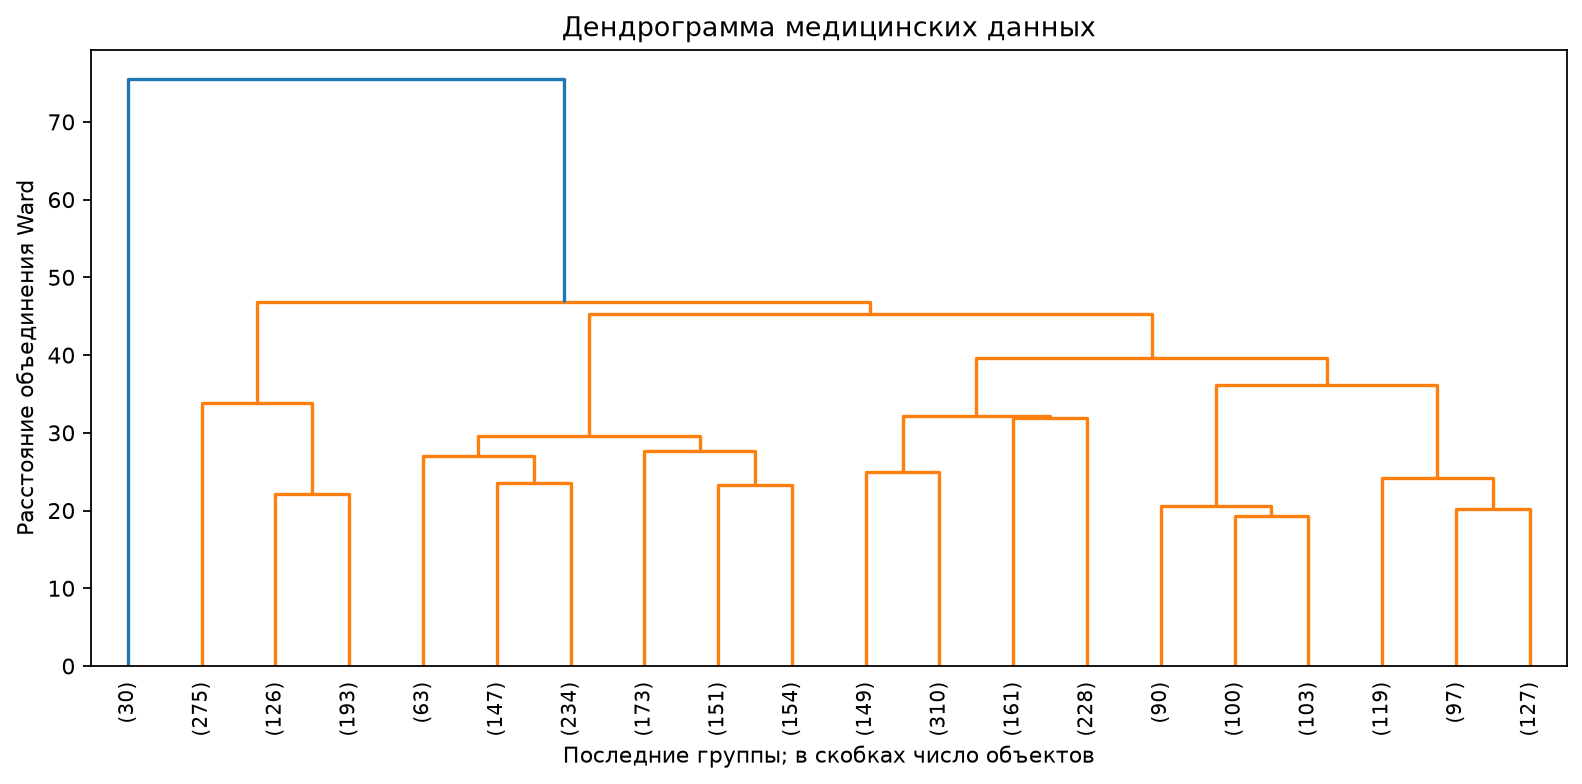

,left,right,distance,count
0,6042.0,6046.0,36.198,636.0
1,6052.0,6054.0,39.687,1484.0
2,6050.0,6055.0,45.237,2406.0
3,6053.0,6056.0,46.890,3000.0
4,6020.0,6057.0,75.525,3030.0


,Disease,cluster
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
3026,0,1
3027,0,1
3028,0,1
3029,0,1


cluster
0    3000
1      30
Name: count, dtype: int64

,age,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,symptom_score,CRP_mg_L,WBC_10e9_L
cluster,,,,,,,,
0,53.103,26.479,122.435,199.825,94.399,2.040,1.119,6.818
1,60.633,25.120,120.300,486.840,91.167,2.053,26.742,7.382


silhouette      0.65385
ARI             0.01284
AMI            -0.00139
homogeneity     0.00086
completeness    0.00128
dtype: float64

In [8]:
linked = linkage(X_medical_scaled, method='ward')
plt.figure(figsize=(10, 5))
dendrogram(linked, truncate_mode='lastp', p=20,
           show_leaf_counts=True, leaf_rotation=90, leaf_font_size=9)
plt.xlabel('Последние группы; в скобках число объектов')
plt.ylabel('Расстояние объединения Ward')
plt.title('Дендрограмма медицинских данных')
plt.tight_layout()
plt.show()
display(pd.DataFrame(linked[-5:],
    columns=['left', 'right', 'distance', 'count']).round(3))
hierarchical = AgglomerativeClustering(n_clusters=2, linkage='ward')
labels_hierarchical = hierarchical.fit_predict(X_medical_scaled)
assignments_hierarchical = medical.copy()
assignments_hierarchical['cluster'] = labels_hierarchical
display(assignments_hierarchical[['Disease', 'cluster']])
print('Численность агломеративных кластеров:')
display(assignments_hierarchical.groupby('cluster').size().rename('count'))
means_hierarchical = assignments_hierarchical.groupby('cluster')[X.columns].mean()
display(means_hierarchical.round(3))
metrics_hierarchical = pd.Series({
    'silhouette': silhouette_score(X_medical_scaled, labels_hierarchical),
    'ARI': adjusted_rand_score(y_true, labels_hierarchical),
    'AMI': adjusted_mutual_info_score(y_true, labels_hierarchical),
    'homogeneity': homogeneity_score(y_true, labels_hierarchical),
    'completeness': completeness_score(y_true, labels_hierarchical)})
display(metrics_hierarchical.round(5))

## Выводы
На синтетических данных лучший результат получен при k = 3: силуэт 0,7034. Метод локтя согласуется с этим числом групп.

Для medical_diagnosis.csv после удаления одного дубликата использованы 3030 объектов и восемь стандартизованных числовых признаков. Disease и категориальные столбцы не участвовали в обучении. Заполнение пропусков не применялось, поскольку пропусков нет.

K-means при k = 2 выделил группы из 1587 и 1443 объектов, различающиеся прежде всего возрастом. Низкий силуэт 0,1068 указывает на слабое разделение. Метод Ward при k = 2 выделил основную группу из 3000 объектов и малую из 30. У малой группы средний CRP = 26,742 мг/л против 1,119 мг/л, холестерин = 486,840 мг/дл против 199,825 мг/дл. Разрыв на дендрограмме перед последним объединением: 46,890 против 75,525. Силуэт Ward = 0,6538, ARI = 0,01284, AMI = -0,00139.

Для выделения компактной группы с высокими лабораторными показателями в данном эксперименте полезнее Ward. Высокий внутренний силуэт не означает восстановления Disease: внешние метрики обоих методов близки к нулю. Обнаруженные группы не являются медицинским диагнозом. Среди 3030 объектов только 49 имеют Disease = 1; выраженный дисбаланс также требует осторожной интерпретации внешних метрик.